<a href="https://colab.research.google.com/github/ludawg329/ITAI2373-NewsBot-Midterm/blob/main/MarketNewsBot_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🤖 Market NewsBot Intelligence System
## ITAI 2373 (Natural Language Processing) - Mid-Term Project

**Author:** Wayne Lu (individual project, no team members)  
**Date:** October 17, 2026  
**Course:** ITAI 2373, Houston Community College  
**Instructor:** Professor Sridhar Ganti  
**GitHub Repository:** https://github.com/ludawg329/ITAI2373-NewsBot-Midterm  
**🎥 Video demo:** [MT_Video_Group_Individual_Wayne_Lu_ITAI2373.mp4](https://github.com/ludawg329/ITAI2373-NewsBot-Midterm/blob/main/ITAI2373-NewsBot-Midterm/demo/MT_Video_Group_Individual_Wayne_Lu_ITAI2373.mp4)  
**Reflection and report:** at the end of this notebook, and in the repo as `REFLECTION.md` and `REPORT.md`

---

## 🎯 Project Overview

This notebook is my Market NewsBot, an NLP system for market and financial news that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Reuters market topics (Earnings, Acquisitions, Crude Oil, Money/FX, Interest Rates, Trade))
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [x] **Module 1:** NLP applications and real-world context
- [x] **Module 2:** Text preprocessing pipeline
- [x] **Module 3:** TF-IDF feature extraction
- [x] **Module 4:** POS tagging analysis
- [x] **Module 5:** Syntax parsing and semantic analysis
- [x] **Module 6:** Sentiment and emotion analysis
- [x] **Module 7:** Text classification system
- [x] **Module 8:** Named Entity Recognition

---

> ⚠️ **Informational only, not investment, tax, or legal advice.**

> 📰 **Dataset:** Reuters-21578 full newswire articles, single-label, 6 topics, 1,703 articles after duplicate removal. *Dataset approval was requested from the instructor through Canvas on 2026-10-14.*

## 🎥 Video Demo

**[Watch the narrated demo: MT_Video_Group_Individual_Wayne_Lu_ITAI2373.mp4](https://github.com/ludawg329/ITAI2373-NewsBot-Midterm/blob/main/ITAI2373-NewsBot-Midterm/demo/MT_Video_Group_Individual_Wayne_Lu_ITAI2373.mp4)** (about 5 min 13 s, 1280x720, hosted in this repo under `demo/`; GitHub plays it in the browser).

The video covers the goal and the repository layout, the data, a live run on **new** articles (the latest Federal Reserve and SEC press releases, plus two clearly marked synthetic test headlines for the alert rules), the key charts from this notebook, the results, the business value, and the limits. The live run can be repeated with `python demo/live_demo.py` from the project folder.


## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [1]:
# Install required packages (run this cell first in Colab; already installed locally)
# !pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly feedparser
# !python -m spacy download en_core_web_sm
import nltk
for pkg in ['punkt','punkt_tab','stopwords','wordnet','vader_lexicon','averaged_perceptron_tagger','averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)
print("✅ NLTK data ready")

✅ NLTK data ready


In [2]:
import pandas as pd, numpy as np, re, warnings, datetime as dt
import matplotlib.pyplot as plt, seaborn as sns
from wordcloud import WordCloud
from collections import Counter, defaultdict
warnings.filterwarnings('ignore')
import spacy, nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
nlp = spacy.load('en_core_web_sm')
plt.rcParams['figure.figsize'] = (10, 5)
DISCLAIMER = "Informational only, not investment, tax, or legal advice."
print("✅ Libraries loaded |", DISCLAIMER)

✅ Libraries loaded | Informational only, not investment, tax, or legal advice.


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

### 💼 Business Case: Market NewsBot for Individual Investors & Small-Business Owners

**Target user:** an individual investor or trader who follows a watchlist (for example TSLA, HOOD, index and chip stocks), or a small-business owner who needs market, rate, and small-business news.

**Problem:** hundreds of market headlines per day; only a few move positions, taxes, or business plans.

**Value proposition:** automatically (1) route each headline into a market category, (2) tag it bullish/bearish, (3) pull out companies, tickers, $ amounts, % moves and dates, (4) match it to a configurable watchlist, and (5) roll it into a weekly Monday digest plus same-day alerts, with separate **Trading / Macro / Business** sections.

**Industry context:** this mirrors Bloomberg/Refinitiv news analytics and sell-side sentiment feeds, built here with free, open tools.

> ⚠️ **Disclaimer:** Informational only, not investment, tax, or legal advice.

In [3]:
# ⚙️ Configurable example watchlist and guardrails
WATCHLIST = {
    'Trading': {
        'tickers': {'TSLA': ['tesla','tsla'], 'HOOD': ['robinhood','hood'],
                    'TSM': ['tsmc','taiwan semiconductor'], 'SSNLF': ['samsung'], 'INTC': ['intel'], 'TXN': ['texas instruments']},
        'indices': ['s&p 500','s&p','spx','nasdaq','russell 2000','eafe','10-year','10y','vix','sox','semiconductor index'],
        'themes': ['ai','artificial intelligence','robotics','semiconductor','chip','options','earnings','upgrade','downgrade'],
    },
    'Macro': {
        'macro': ['fomc','fed','cpi','pce','inflation','jobs','payrolls','unemployment','prime rate','mortgage','treasury','yield'],
        'tax': ['irs','wash sale','section 1256','tax'],
        'real_estate': ['real estate','home sales'],
    },
    'Business': {  # small-business news, kept separate from trading news
        'small_business': ['small business','franchise'],
        'financing': ['sba','7(a)'],
        'business_tax': ['franchise tax'],
    },
    'DataCenters': {  # Data center builds segment
        'tickers': ['vrt','etn','gev','vst','ceg','nrg','eqix','dlr','pwr','eme','fix','anet','cien','cohr','lite','crdo','crwv','nbis',
                    'vertiv','eaton','ge vernova','vistra','constellation energy','equinix','digital realty','quanta','emcor','comfort systems',
                    'arista','ciena','coherent','lumentum','credo','coreweave','nebius'],
        'keywords': ['data center','datacenter','hyperscale','hyperscaler','megawatt','gigawatt','campus','capex','cooling',
                     'power purchase agreement','stargate','abilene'],
    },
    'Space': {  # Space segment: every hit carries a compliance-check flag
        'tickers': ['rklb','asts','lunr','pl','rdw','irdm','vsat','ba','lmt','noc','rocket lab','ast spacemobile','intuitive machines',
                    'planet labs','redwire','iridium','viasat','boeing','lockheed','northrop'],
        'keywords': ['launch','satellite','spaceflight','orbit','rocket'],
        # Starlink direct-to-cell / mobile topic (news only)
        'd2c': ['starlink','direct to cell','direct-to-cell','t-satellite','t-mobile','echostar','spectrum','fcc','globalstar',
                'tmus','sats','gsat','at&t','verizon'],
    },
    'Telecom': {  # Telecom carriers segment, linked to Starlink direct-to-cell topic
        'tickers': ['vz','tmus','vod','dtegy','amx','oran','tef','bce','rci','tu','nttyy','skm','verizon','t-mobile','vodafone',
                    'deutsche telekom','america movil','orange','telefonica','rogers','telus','ntt','sk telecom','bharti','airtel','at&t'],
        'keywords': ['wireless carrier','5g','spectrum','subscribers','direct to cell','direct-to-cell'],
    },
    'Regulatory': ['sec','finra','pattern day trader','rule 4210','t+1','options margin','federal register'],
}
ALERT_RULES = {
    'big_move_pct': 7.0,  # alert on >7% day moves for watch tickers
    'event_keywords': ['earnings','upgrade','downgrade','guidance','fomc','rate decision','cpi','halt'],
}
# Example restricted-securities list (compliance filter: some employers restrict which stocks staff may hold)
ETHICS_STATUS = {
    'BLOCK': ['BA','LMT','NOC','VSAT','SPACEX','SPCX'],
    'FLAG':  ['IRDM','RDW','RKLB','ETN','UFO','ARKX','ITA'],   # needs compliance confirmation
    'LOW':   ['ASTS','LUNR','PL'],
}
ETHICS_ALIASES = {'BOEING':'BA','LOCKHEED':'LMT','NORTHROP':'NOC','VIASAT':'VSAT','IRIDIUM':'IRDM','REDWIRE':'RDW','ROCKET LAB':'RKLB',
                  'EATON':'ETN','STARLINK':'SPACEX','AST SPACEMOBILE':'ASTS','INTUITIVE MACHINES':'LUNR','PLANET LABS':'PL'}
def ethics_status(text):
    T = ' ' + str(text).upper() + ' '
    found = {}
    for st, syms in ETHICS_STATUS.items():
        for s_ in syms:
            if re.search(r'(?<![A-Z])\$?'+re.escape(s_)+r'(?![A-Z])', T): found[s_] = st
    for a, s_ in ETHICS_ALIASES.items():
        if a in T: found[s_] = next(st for st, l in ETHICS_STATUS.items() if s_ in l)
    return found
# Compliance filter: holdings that must be flagged or blocked (restricted list)
BLOCKED_HOLDINGS = ['spacex','spcx']
# Data-handling guardrails
GUARDRAILS = [
    'Informational only, not investment, tax, or legal advice.',
    'Use official APIs/RSS only (SEC EDGAR with declared User-Agent, Federal Register, Federal Reserve, BLS). No paywall scraping.',
    'Store headline + short excerpt (<=200 chars) + link only.',
    'Never log account numbers (redacted automatically).',
    'Business news labeled separately from trading news.',
]
DC_KEYWORDS = WATCHLIST['DataCenters']['keywords']
def is_data_center(text):
    t = str(text).lower()
    return any(re.search(r'(?<![a-z])'+re.escape(k)+r'(?![a-z])', t) for k in DC_KEYWORDS)
def redact_accounts(text):
    """Mask account-number-like digit runs (8+ digits) before anything is logged."""
    return re.sub(r'\b\d[\d-]{7,}\d\b', '[REDACTED]', str(text))
def ethics_flag(text):
    t = str(text).lower()
    return [b for b in BLOCKED_HOLDINGS if re.search(r'\b'+re.escape(b)+r'\b', t)]
print("Guardrails:"); [print(" -", g) for g in GUARDRAILS]
print("Redaction test:", redact_accounts("acct 1234567890 moved"))

Guardrails:
 - Informational only, not investment, tax, or legal advice.
 - Use official APIs/RSS only (SEC EDGAR with declared User-Agent, Federal Register, Federal Reserve, BLS). No paywall scraping.
 - Store headline + short excerpt (<=200 chars) + link only.
 - Never log account numbers (redacted automatically).
 - Business news labeled separately from trading news.
Redaction test: acct [REDACTED] moved


In [4]:
# Real public dataset: Reuters-21578 (ModApte split, Distribution 1.0) full newswire articles.
# Same corpus as Kaggle "thedevastator/uncovering-financial-insights-with-the-reuters-2" (CC0); loaded here from the
# official NLTK data mirror so no Kaggle login is needed.
import os, zipfile, urllib.request, html, io
from nltk.corpus import reuters
try:
    reuters.fileids()
except LookupError:
    url = 'https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/corpora/reuters.zip'
    d = os.path.expanduser('~/nltk_data/corpora'); os.makedirs(d, exist_ok=True)
    urllib.request.urlretrieve(url, d + '/reuters.zip'); zipfile.ZipFile(d + '/reuters.zip').extractall(d)
    from importlib import reload; import nltk.corpus; reuters = nltk.corpus.reuters
TOPIC_NAMES = {'earn':'Earnings','acq':'Acquisitions (M&A)','crude':'Crude Oil','money-fx':'Money/FX',
               'interest':'Interest Rates','trade':'Trade'}
rows = []
for fid in reuters.fileids():
    cs = reuters.categories(fid)
    if len(cs) == 1 and cs[0] in TOPIC_NAMES:          # single-label docs only
        txt = reuters.raw(fid).strip()
        title, _, body = txt.partition('\n')
        rows.append({'doc_id': fid, 'reuters_topic': cs[0], 'title': html.unescape(title.strip()).title(),
                     'content': html.unescape(re.sub(r'\s+', ' ', body).strip())})
raw = pd.DataFrame(rows)
raw['category'] = raw['reuters_topic'].map(TOPIC_NAMES)
raw = raw.replace('', np.nan).dropna(subset=['title','content','category'])
raw = raw[raw['content'].str.split().str.len() >= 20]   # drop stub items (e.g. "Shr 10 cts vs 8 cts" only)
# Remove exact duplicates (Reuters re-sends identical stories) BEFORE sampling/splitting to avoid train/test leakage
_norm = (raw['title'] + ' ' + raw['content']).str.lower().str.replace(r'\s+', ' ', regex=True)
print(f"Exact duplicate articles removed: {_norm.duplicated().sum()}")
raw = raw[~_norm.duplicated()].reset_index(drop=True)
print("Single-label docs available per topic:\n", raw['category'].value_counts())
# Balanced sample: up to 333 per class (6 x 333 <= 2,000); smaller classes use all their docs
PER_CLASS = 2000 // len(TOPIC_NAMES)
df = pd.concat([g.sample(n=min(len(g), PER_CLASS), random_state=42) for _, g in raw.groupby('category')],
               ignore_index=True)
df['full_text'] = df['title'] + '. ' + df['content']
assert len(df) <= 2000 and df[['title','content','category']].isnull().sum().sum() == 0
df.to_csv('market_newsbot_dataset.csv', index=False)
# Sentiment labels: Reuters has none, so the bullish/bearish model is trained on Financial PhraseBank
# (Malo et al. 2014; HF takala/financial_phrasebank, CC BY-NC-SA 3.0): ~4.2k financial-news sentences, >=66% annotator agreement
FPB_URL = 'https://huggingface.co/datasets/takala/financial_phrasebank/resolve/main/data/FinancialPhraseBank-v1.0.zip'
_z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(FPB_URL, timeout=60).read()))
_lines = _z.read('FinancialPhraseBank-v1.0/Sentences_66Agree.txt').decode('latin-1').splitlines()
sent_raw = pd.DataFrame([l.rsplit('@', 1) for l in _lines if '@' in l], columns=['text', 'label'])
sent_raw['sentiment'] = sent_raw['label'].str.strip().map({'negative':'Bearish','positive':'Bullish','neutral':'Neutral'})
sent_raw = sent_raw.dropna().drop_duplicates('text').reset_index(drop=True)
print(f"Reuters single-label pool: {raw.shape} -> sampled {df.shape} across {df.category.nunique()} categories")
print(f"Sentiment corpus (Financial PhraseBank): {sent_raw.shape}", sent_raw.sentiment.value_counts().to_dict())

Exact duplicate articles removed: 53
Single-label docs available per topic:
 category
Earnings              3055
Acquisitions (M&A)    2049
Crude Oil              317
Trade                  286
Money/FX               249
Interest Rates         185
Name: count, dtype: int64
Reuters single-label pool: (6141, 5) -> sampled (1703, 6) across 6 categories
Sentiment corpus (Financial PhraseBank): (4211, 3) {'Neutral': 2529, 'Bullish': 1168, 'Bearish': 514}


### 📥 Alternative real datasets on Kaggle (verified 2026-10-14 via Kaggle API metadata)
| Dataset | URL | Content | Size / License |
|---|---|---|---|
| Financial News Headlines Data (CNBC, Guardian, Reuters) | https://www.kaggle.com/datasets/notlucasp/financial-news-headlines | Headlines, Time, Description (CNBC/Reuters/Guardian, 2017-2020) | ~11.8 MB, CC0 |
| Sentiment Analysis for Financial News (FinancialPhraseBank) | https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news | Sentiment (positive/negative/neutral), News Headline (~4.8k rows) | ~2.7 MB, CC BY-NC-SA 4.0 |
| Daily Financial News for 6000+ Stocks | https://www.kaggle.com/datasets/miguelaenlle/massive-stock-news-analysis-db-for-nlpbacktests | headline, url, publisher, date, stock (~4M rows, 2009-2020) | ~886 MB, CC0 (sample to <=2,000) |
| Daily News for Stock Market Prediction | https://www.kaggle.com/datasets/aaron7sun/stocknews | 25 daily Reddit WorldNews headlines + DJIA label | ~14.9 MB, CC BY-NC-SA 4.0 |

**This project uses Reuters-21578 full articles** (Kaggle mirror: https://www.kaggle.com/datasets/thedevastator/uncovering-financial-insights-with-the-reuters-2, CC0), loaded from the NLTK data mirror so no credentials are needed. Backup full-article set: https://www.kaggle.com/datasets/jeet2016/us-financial-news-articles. Dataset approval request sent to the instructor via Canvas on 2026-10-14. Kaggle needs a `kaggle.json` API key:
```python
!pip install kaggle
from google.colab import files; files.upload()          # upload kaggle.json
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d notlucasp/financial-news-headlines --unzip
cnbc = pd.read_csv('cnbc_headlines.csv').dropna()      # also reuters_headlines.csv, guardian_headlines.csv
!kaggle datasets download -d ankurzing/sentiment-analysis-for-financial-news --unzip
fpb = pd.read_csv('all-data.csv', encoding='latin-1', names=['sentiment','headline'])
```

category
Acquisitions (M&A)    333
Earnings              333
Crude Oil             317
Trade                 286
Money/FX              249
Interest Rates        185
Name: count, dtype: int64

🏗️ Data Center Builds: 5 of 6141 Reuters (1987) docs match data-center keywords -> handled by a rule-based router in the final system

Missing values:
 title       0
content     0
category    0
dtype: int64

Length stats:
        char_len  word_len
count    1703.0    1703.0
mean     1038.0     171.7
std       945.4     154.4
min       124.0      25.0
25%       406.5      68.0
50%       631.0     106.0
75%      1314.5     219.5
max      5583.0     950.0


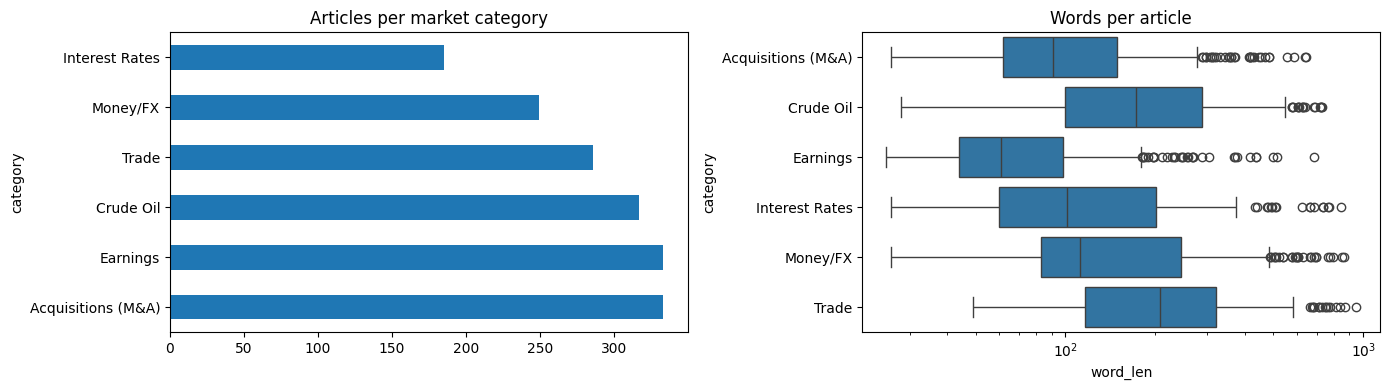


Sample:
       category                                            title
708    Earnings   Franklin Pennsylvania U.S. Sets Initial Payout
1353   Money/FX           Miyazawa Says U.S. Likely To Intervene
491   Crude Oil                 Ghana To Buy Crude Oil From Iran
703    Earnings     Weeks Petroleum Ltd <Wpma.Mel> Calendar 1986
1286   Money/FX  Louvre Reaffirmation Not Enough - U.K. Analysts

Example full article:
 Waste <Wmx> Ends Offer For Chemlawn <Chem>. Waste Management Inc said its wholly owned subsidiary, WMX Acquisition Corp, ended its tender offer to buy shares of ChemLawn Corp at 35 dlrs a share. All shares tendered to Waste Management will be returned to shareholders as soon as practical, it said. Earlier this week, ChemLawn agreed to accept a merger proposal at 36.50 dlrs a share from Ecolab Inc in a transaction valued at about 370 mln dlrs.

ℹ️ Full newswire articles (avg ~172 words, median 106). Language: English. Period: 1987.


In [5]:
print(df['category'].value_counts())
dc_full = raw[raw['content'].apply(is_data_center)]
print(f"\n🏗️ Data Center Builds: {len(dc_full)} of {len(raw)} Reuters (1987) docs match data-center keywords -> handled by a rule-based router in the final system")
print("\nMissing values:\n", df[['title','content','category']].isnull().sum())
df['char_len'] = df['full_text'].str.len(); df['word_len'] = df['full_text'].str.split().str.len()
print("\nLength stats:\n", df[['char_len','word_len']].describe().round(1))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df['category'].value_counts().plot.barh(ax=ax[0], title='Articles per market category')
sns.boxplot(data=df, y='category', x='word_len', ax=ax[1]); ax[1].set_title('Words per article'); ax[1].set_xscale('log')
plt.tight_layout(); plt.show()
print("\nSample:"); print(df.sample(5, random_state=1)[['category','title']].to_string())
print("\nExample full article:\n", df.full_text.iloc[0][:800])
print(f"\nℹ️ Full newswire articles (avg ~{round(df.word_len.mean())} words, median {int(df.word_len.median())}). Language: English. Period: 1987.")

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [24]:
import nltk
for _p in ['punkt','punkt_tab','stopwords','wordnet','vader_lexicon','averaged_perceptron_tagger','averaged_perceptron_tagger_eng']:
    nltk.download(_p, quiet=True)
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
# Keep finance-meaningful words that generic stoplists drop
stop_words -= {'up','down','above','below','over','under','no','not','more','most','off'}
stop_words |= {'rt','amp','via','say','says','said'}
def clean_text(text):
    """Normalize raw market text: URLs, HTML entities, cashtags, numbers, punctuation."""
    if not isinstance(text, str) or not text.strip(): return ''
    t = text.replace('&amp;', '&')
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    t = re.sub(r'\$([A-Za-z]{1,5})\b', r' ticker_\1 ', t)          # $TSLA -> ticker_TSLA
    t = re.sub(r'(\d+(\.\d+)?)\s?%', ' pctnum ', t)                # 5.2% -> pctnum
    t = re.sub(r'\$\s?\d[\d,.]*\s?(billion|million|bn|mln|b|m|k)?', ' moneynum ', t, flags=re.I)
    t = re.sub(r'[@#]\w+', ' ', t)
    t = t.lower()
    t = re.sub(r'[^a-z_\s]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()
def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    tokens = word_tokenize(clean_text(text))
    tokens = [w for w in tokens if len(w) > 1]
    if remove_stopwords: tokens = [w for w in tokens if w not in stop_words]
    if lemmatize: tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return ' '.join(tokens)
for s in ["$TSLA jumps 8.5% after Q3 deliveries beat; https://t.co/x", "", None, "Fed hikes by 0.75% &amp; signals $1.2 billion QT"]:
    print(repr(s), '->', repr(preprocess_text(s)))

'$TSLA jumps 8.5% after Q3 deliveries beat; https://t.co/x' -> 'ticker_tsla jump pctnum delivery beat'
'' -> ''
None -> ''
'Fed hikes by 0.75% &amp; signals $1.2 billion QT' -> 'fed hike pctnum signal moneynum qt'


In [7]:
df['processed_text'] = df['full_text'].apply(preprocess_text)
df = df[df['processed_text'].str.len() > 0].reset_index(drop=True)
print("Docs after preprocessing:", len(df))
print(df[['content','processed_text']].head(5).to_string())
print("Avg tokens after cleaning:", round(df.processed_text.str.split().str.len().mean(), 1))

Docs after preprocessing: 1703
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [8]:
# Parameter optimization: small grid over n-grams / min_df / sublinear tf, scored by 5-fold CV
best = None
for ngr in [(1,1),(1,2)]:
    for mindf in [1,2]:
        for sub in [False, True]:
            pipe = Pipeline([('tfidf', TfidfVectorizer(ngram_range=ngr, min_df=mindf, sublinear_tf=sub, max_features=5000)),
                             ('clf', LinearSVC())])
            sc = cross_val_score(pipe, df.processed_text, df.category, cv=5, scoring='f1_macro').mean()
            print(f"ngram={ngr} min_df={mindf} sublinear={sub}: macro-F1={sc:.3f}")
            if best is None or sc > best[0]: best = (sc, ngr, mindf, sub)
print("Best TF-IDF params:", best)
tfidf_vectorizer = TfidfVectorizer(ngram_range=best[1], min_df=best[2], sublinear_tf=best[3], max_features=5000)
tfidf_matrix = tfidf_vectorizer.fit_transform(df['processed_text'])
feature_names = tfidf_vectorizer.get_feature_names_out()
print("TF-IDF matrix:", tfidf_matrix.shape)

ngram=(1, 1) min_df=1 sublinear=False: macro-F1=0.946
ngram=(1, 1) min_df=1 sublinear=True: macro-F1=0.943
ngram=(1, 1) min_df=2 sublinear=False: macro-F1=0.944
ngram=(1, 1) min_df=2 sublinear=True: macro-F1=0.944
ngram=(1, 2) min_df=1 sublinear=False: macro-F1=0.949
ngram=(1, 2) min_df=1 sublinear=True: macro-F1=0.949
ngram=(1, 2) min_df=2 sublinear=False: macro-F1=0.949
ngram=(1, 2) min_df=2 sublinear=True: macro-F1=0.946
Best TF-IDF params: (np.float64(0.9493734971058453), (1, 2), 1, False)
TF-IDF matrix: (1703, 5000)


Acquisitions (M&A)  : share, inc, company, corp, dlrs, acquisition, mln, offer, mln dlrs, stock
Crude Oil           : oil, crude, barrel, price, opec, bpd, crude oil, dlrs, production, ecuador
Earnings            : ct, mln, net, loss, shr, mln mln, ct net, rev, dlrs, profit
Interest Rates      : rate, pct, bank, prime, interest rate, interest, pct pct, rate pct, prime rate, cut
Money/FX            : stg, bank, mln stg, currency, market, dollar, money, money market, exchange, rate
Trade               : trade, japan, billion, export, japanese, import, ec, would, surplus, tariff


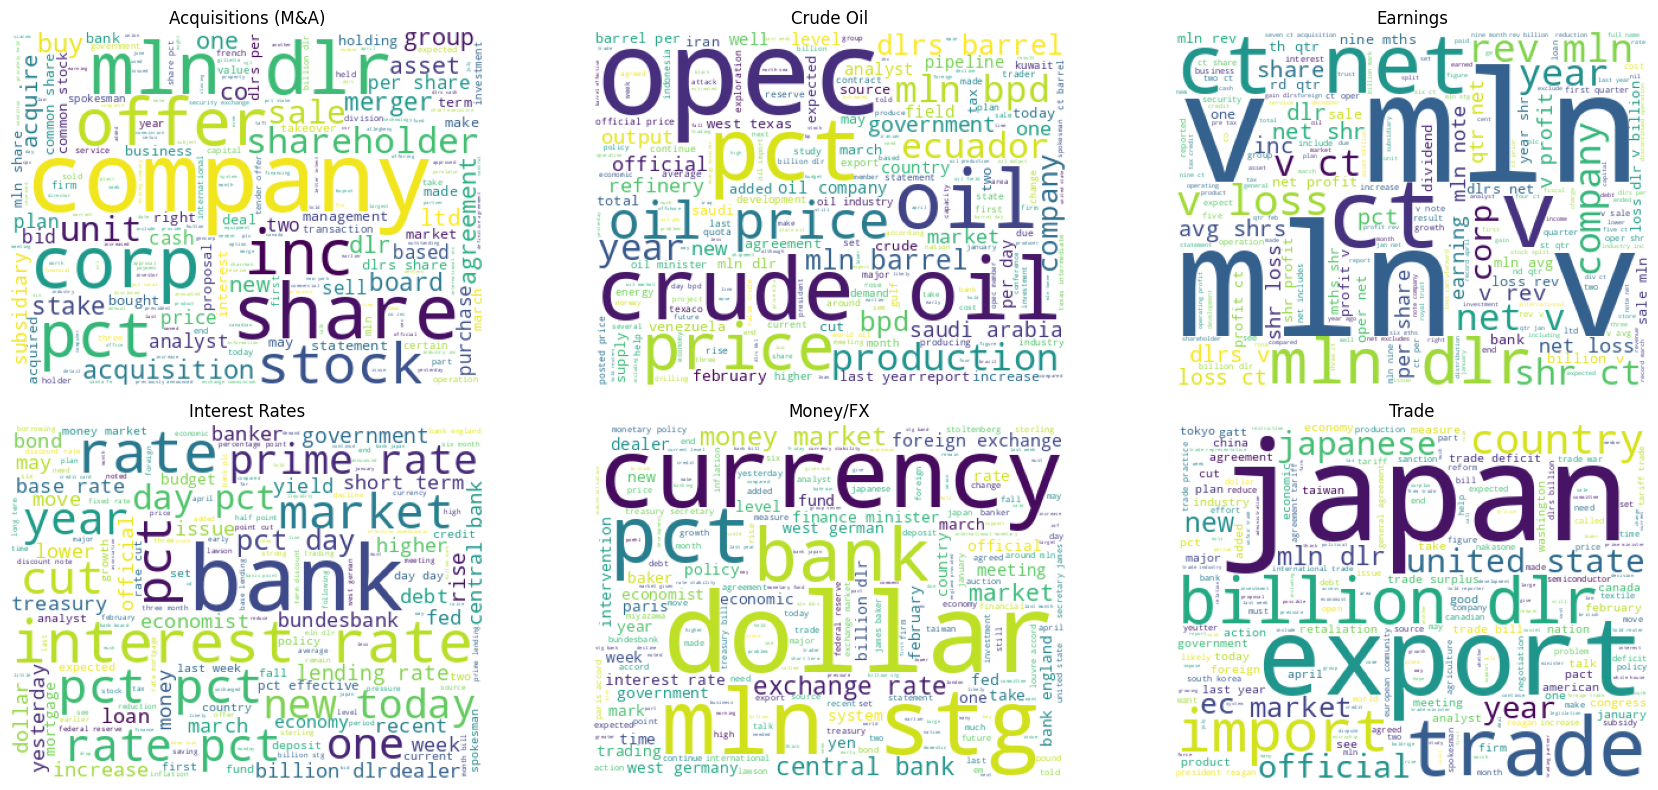

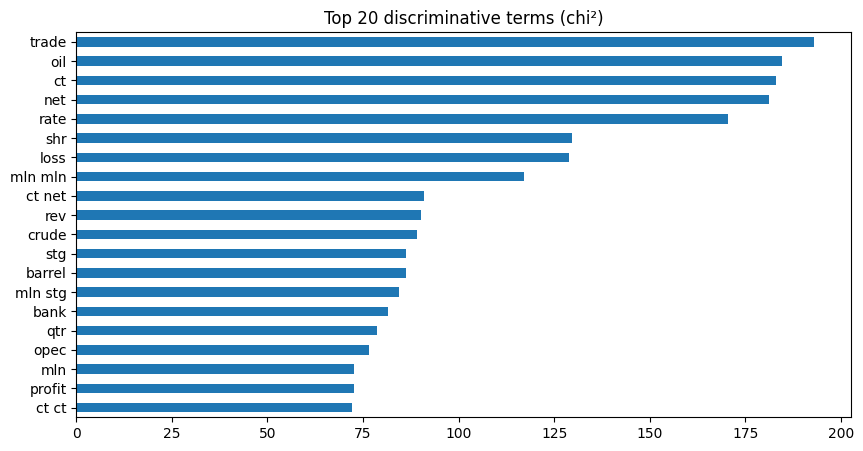

In [9]:
cats = sorted(df.category.unique())
top_terms = {}
for c in cats:
    m = np.asarray(tfidf_matrix[(df.category == c).values].mean(axis=0)).ravel()
    top_terms[c] = [feature_names[i] for i in m.argsort()[::-1][:10]]
    print(f"{c:20s}: {', '.join(top_terms[c])}")
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cats):
    text = ' '.join(df.loc[df.category == c, 'processed_text'])
    ax.imshow(WordCloud(width=400, height=300, background_color='white').generate(text)); ax.set_title(c); ax.axis('off')
plt.tight_layout(); plt.show()
# Feature importance: chi-square
chi, p = chi2(tfidf_matrix, df.category)
imp = pd.Series(chi, index=feature_names).sort_values(ascending=False).head(20)
imp[::-1].plot.barh(title='Top 20 discriminative terms (chi²)'); plt.show()

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [10]:
def pos_profile(text):
    tags = pos_tag(word_tokenize(re.sub(r'https?://\S+', '', str(text))))
    groups = {'NOUN':'NN','VERB':'VB','ADJ':'JJ','ADV':'RB','NUM':'CD','PROPN':'NNP'}
    n = max(len(tags), 1)
    out = {k: sum(1 for _, t in tags if t.startswith(v) and (k != 'NOUN' or not t.startswith('NNP')))/n for k, v in groups.items()}
    return out
pos_df = pd.DataFrame(df['full_text'].apply(pos_profile).tolist())
pos_df['category'] = df['category']
print(pos_df.head())
# Grammatical patterns: most common POS bigrams
bigrams = Counter()
for t in df.full_text.head(300):
    tg = [x[1] for x in pos_tag(word_tokenize(re.sub(r'https?://\S+','',t)))]
    bigrams.update(zip(tg, tg[1:]))
print("Top POS bigrams:", bigrams.most_common(10))

       NOUN      VERB       ADJ       ADV       NUM     PROPN  \
0  0.179775  0.123596  0.011236  0.056180  0.033708  0.258427   
1  0.163265  0.081633  0.020408  0.020408  0.040816  0.448980   
2  0.195652  0.184783  0.032609  0.010870  0.054348  0.195652   
3  0.208955  0.104478  0.044776  0.029851  0.044776  0.179104   
4  0.199717  0.185552  0.062323  0.022663  0.021246  0.107649   

             category  
0  Acquisitions (M&A)  
1  Acquisitions (M&A)  
2  Acquisitions (M&A)  
3  Acquisitions (M&A)  
4  Acquisitions (M&A)  
Top POS bigrams: [(('NNP', 'NNP'), 4476), (('NN', 'IN'), 1919), (('DT', 'NN'), 1886), (('IN', 'DT'), 1393), (('IN', 'NNP'), 1124), (('JJ', 'NN'), 966), (('NN', 'NN'), 811), (('NNP', 'VBD'), 708), (('.', 'NNP'), 680), (('TO', 'VB'), 676)]


                     NOUN   VERB    ADJ    ADV    NUM  PROPN
category                                                    
Acquisitions (M&A)  0.180  0.126  0.049  0.018  0.033  0.243
Crude Oil           0.212  0.129  0.062  0.020  0.040  0.169
Earnings            0.268  0.066  0.087  0.013  0.193  0.201
Interest Rates      0.215  0.111  0.094  0.020  0.049  0.177
Money/FX            0.216  0.127  0.068  0.024  0.042  0.141
Trade               0.200  0.137  0.069  0.024  0.039  0.139


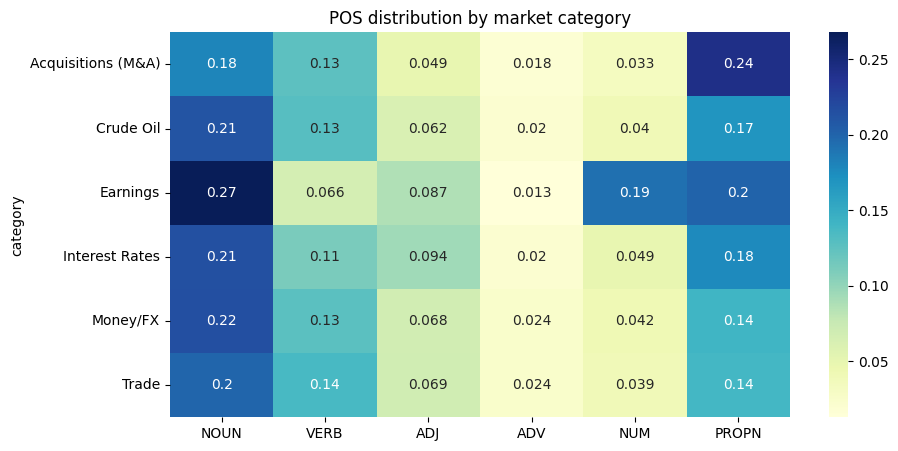

Writing-style notes: highest NUM share -> Earnings | highest VERB share -> Trade | highest PROPN share -> Acquisitions (M&A)


In [11]:
pos_by_cat = pos_df.groupby('category').mean().round(3)
print(pos_by_cat)
sns.heatmap(pos_by_cat, annot=True, cmap='YlGnBu'); plt.title('POS distribution by market category'); plt.show()
print("Writing-style notes: highest NUM share ->", pos_by_cat.NUM.idxmax(),
      "| highest VERB share ->", pos_by_cat.VERB.idxmax(), "| highest PROPN share ->", pos_by_cat.PROPN.idxmax())

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [12]:
def syntax_features(text):
    doc = nlp(re.sub(r'https?://\S+', '', str(text))[:1500])
    svo = []
    for tok in doc:
        if tok.pos_ == 'VERB':
            subj = [w.text for w in tok.lefts if w.dep_ in ('nsubj','nsubjpass')]
            obj = [w.text for w in tok.rights if w.dep_ in ('dobj','attr','pobj','dative')]
            if subj and obj: svo.append((subj[0], tok.lemma_, obj[0]))
    depth = max([len(list(t.ancestors)) for t in doc] or [0])
    return {'svo': svo, 'n_subj': sum(t.dep_.startswith('nsubj') for t in doc), 'n_dobj': sum(t.dep_=='dobj' for t in doc),
            'n_prep': sum(t.dep_=='prep' for t in doc), 'tree_depth': depth,
            'agents': [t.text for t in doc if t.dep_ == 'nsubj'], 'patients': [t.text for t in doc if t.dep_ in ('dobj','nsubjpass')]}
syn = df['full_text'].apply(syntax_features)
syn_df = pd.DataFrame(syn.tolist()); syn_df['category'] = df['category']
print(syn_df.groupby('category')[['n_subj','n_dobj','n_prep','tree_depth']].mean().round(2))
print("\nSample subject-verb-object relations (semantic roles: agent-action-patient):")
for r in [x for x in syn_df.svo if x][:12]: print("  ", r)
verbs = Counter(v for l in syn_df.svo for _, v, _ in l)
print("\nMost common action verbs:", verbs.most_common(15))

                    n_subj  n_dobj  n_prep  tree_depth
category                                              
Acquisitions (M&A)   10.00    5.86   12.87        9.54
Crude Oil            14.79    7.77   19.10        9.44
Earnings              4.49    2.57   10.50        7.50
Interest Rates       10.91    5.59   14.63        8.59
Money/FX             12.61    6.90   16.46        9.23
Trade                16.22   10.01   21.18       10.22

Sample subject-verb-object relations (semantic roles: agent-action-patient):
   [('subsidiary', 'end', 'offer')]
   [('subsidiary', 'complete', 'purchase'), ('Marine', 'have', 'revenues')]
   [('Crrs', 'plan', 'Sale'), ('it', 'buy', 'unit')]
   [('who', 'represent', 'pct')]
   [('it', 'tell', 'SGL'), ('it', 'offer', 'cash'), ('board', 'recommend', 'offer'), ('it', 'deny', 'information'), ('that', 'give', 'to'), ('purchasers', 'give', 'access'), ('management', 'consider', 'buyout'), ('company', 'receive', 'offer'), ('it', 'request', 'information'), ('agr

In [13]:
from spacy import displacy
sample = "Tesla raised its delivery forecast after the Fed cut rates by 25 basis points."
doc = nlp(sample)
try:
    from IPython.display import display, HTML
    display(HTML(displacy.render(doc, style='dep', jupyter=False, options={'compact': True})))
except Exception:
    pass
for t in doc: print(f"{t.text:12s} {t.dep_:10s} head={t.head.text}")

Tesla        nsubj      head=raised
raised       ROOT       head=raised
its          poss       head=forecast
delivery     compound   head=forecast
forecast     dobj       head=raised
after        prep       head=raised
the          det        head=Fed
Fed          nsubj      head=cut
cut          compound   head=rates
rates        pobj       head=after
by           prep       head=rates
25           nummod     head=points
basis        compound   head=points
points       pobj       head=by
.            punct      head=raised


## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

> ⚠️ **Sentiment limitation:** Reuters-21578 has no sentiment labels. The Bullish/Bearish/Neutral model is trained on short Financial PhraseBank sentences (financial-news sentences labeled by finance experts) and applied to whole 1987 newswire articles, so its predictions here are a domain-shifted estimate, not a measured accuracy. The held-out accuracy reported below is on the PhraseBank test sentences only. VADER is shown alongside as a lexicon baseline.

In [14]:
sia = SentimentIntensityAnalyzer()
def analyze_sentiment(text):
    if not text or pd.isna(text): return {'compound':0,'pos':0,'neu':1,'neg':0,'label':'neutral'}
    s = sia.polarity_scores(str(text))
    s['label'] = 'positive' if s['compound'] >= 0.05 else 'negative' if s['compound'] <= -0.05 else 'neutral'
    return s
# Domain model: bullish/bearish classifier trained on Financial PhraseBank (66% agreement)
s_tr, s_te = train_test_split(sent_raw, test_size=0.2, random_state=42, stratify=sent_raw.sentiment)
market_sent_model = Pipeline([('tfidf', TfidfVectorizer(preprocessor=preprocess_text, ngram_range=(1,2), min_df=2, sublinear_tf=True)),
                              ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
market_sent_model.fit(s_tr.text, s_tr.sentiment)
sp = market_sent_model.predict(s_te.text)
print("Bullish/Bearish/Neutral model (held-out):"); print(classification_report(s_te.sentiment, sp))
vader_map = s_te.text.apply(lambda t: {'positive':'Bullish','negative':'Bearish','neutral':'Neutral'}[analyze_sentiment(t)['label']])
print(f"VADER baseline accuracy on same test set: {accuracy_score(s_te.sentiment, vader_map):.3f}")
# Emotional tone lexicon (finance-flavoured fear/greed/uncertainty)
EMOTION_LEX = {'fear': ['fear','panic','crash','plunge','selloff','recession','default','risk','worry','slump','tumble'],
               'greed': ['rally','surge','soar','record','beat','boom','jump','upgrade','bull','gain'],
               'uncertainty': ['may','could','uncertain','volatile','volatility','unclear','probe','investigation','delay'],
               'trust': ['guidance','reaffirm','stable','dividend','approve','approved','agreement']}
def emotion_scores(text):
    toks = preprocess_text(text).split(); n = max(len(toks), 1)
    return {e: sum(t in ws for t in toks)/n for e, ws in EMOTION_LEX.items()}
sentiment_df = df[['category','full_text']].copy()
v = df['full_text'].apply(analyze_sentiment)
sentiment_df['full_sentiment'] = v.apply(lambda s: s['compound']); sentiment_df['pos_score'] = v.apply(lambda s: s['pos'])
sentiment_df['neu_score'] = v.apply(lambda s: s['neu']); sentiment_df['neg_score'] = v.apply(lambda s: s['neg'])
sentiment_df['full_label'] = v.apply(lambda s: s['label'])
sentiment_df['market_sentiment'] = market_sent_model.predict(df['full_text'])
sentiment_df = pd.concat([sentiment_df, pd.DataFrame(df['full_text'].apply(emotion_scores).tolist())], axis=1)
print(sentiment_df.head())

Bullish/Bearish/Neutral model (held-out):
              precision    recall  f1-score   support

     Bearish       0.61      0.71      0.65       103
     Bullish       0.75      0.61      0.67       234
     Neutral       0.83      0.88      0.86       506

    accuracy                           0.78       843
   macro avg       0.73      0.73      0.73       843
weighted avg       0.78      0.78      0.78       843

VADER baseline accuracy on same test set: 0.559
             category                                          full_text  \
0  Acquisitions (M&A)  Waste <Wmx> Ends Offer For Chemlawn <Chem>. Wa...   
1  Acquisitions (M&A)  Tenneco <Tgt> Buys Unisys <Uis> Unit. Tenneco ...   
2  Acquisitions (M&A)  Crown Resources <Crrs> Plans Energy Unit Sale....   
3  Acquisitions (M&A)  <Reser'S Fine Foods Inc> To Go Private. Reser'...   
4  Acquisitions (M&A)  Dart Group Flexible On Supermarkets <Sgl> Bid....   

   full_sentiment  pos_score  neu_score  neg_score full_label  \
0      

                   full_sentiment pos_score neu_score neg_score
                             mean      mean      mean      mean
category                                                       
Acquisitions (M&A)          0.539     0.094     0.884     0.022
Crude Oil                  -0.030     0.078     0.848     0.074
Earnings                    0.270     0.082     0.863     0.055
Interest Rates              0.453     0.089     0.871     0.039
Money/FX                    0.381     0.076     0.885     0.039
Trade                       0.134     0.076     0.857     0.067

Bullish/Bearish mix by category:
 market_sentiment    Bearish  Bullish  Neutral
category                                     
Acquisitions (M&A)    0.030    0.048    0.922
Crude Oil             0.199    0.237    0.565
Earnings              0.351    0.297    0.351
Interest Rates        0.297    0.286    0.416
Money/FX              0.161    0.205    0.635
Trade                 0.119    0.213    0.668


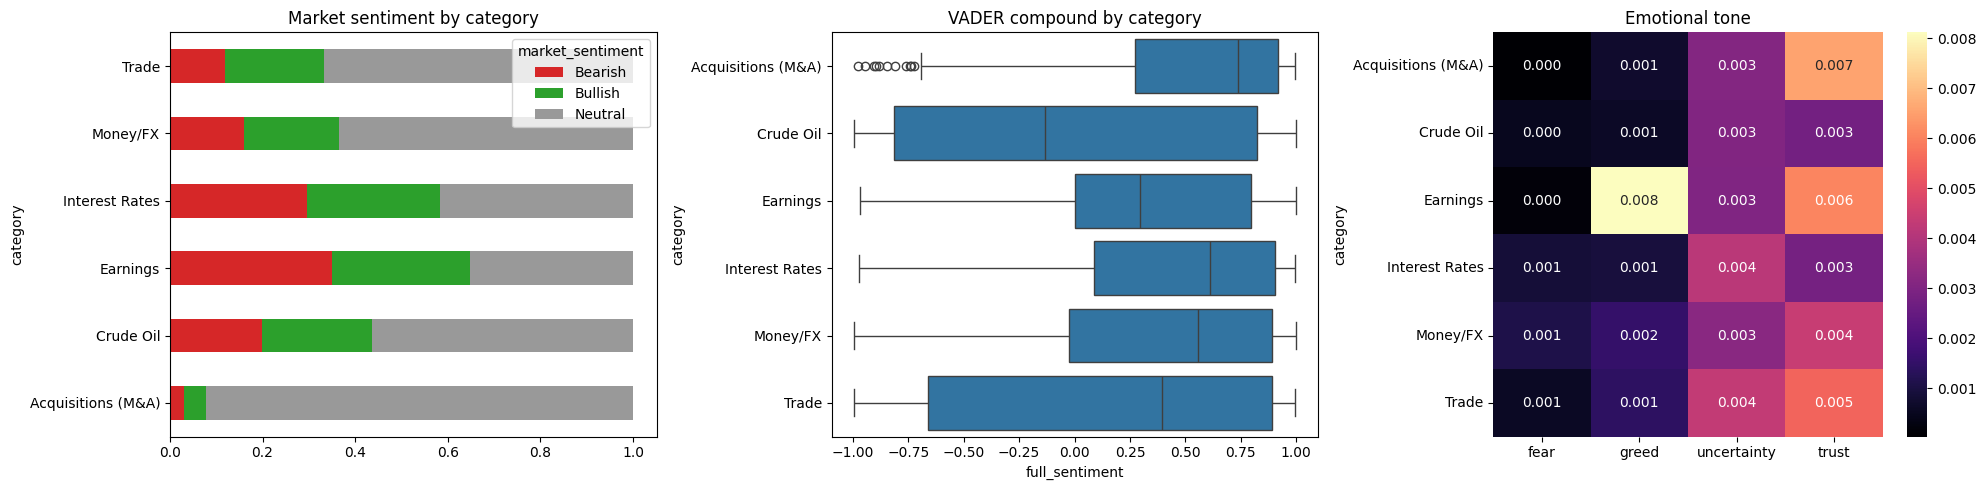

Most bearish category: Earnings | most bullish: Earnings


In [15]:
print(sentiment_df.groupby('category')[['full_sentiment','pos_score','neu_score','neg_score']].agg(['mean']).round(3))
mdist = pd.crosstab(sentiment_df.category, sentiment_df.market_sentiment, normalize='index').round(3)
print("\nBullish/Bearish mix by category:\n", mdist)
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
mdist.plot.barh(stacked=True, ax=ax[0], color=['#d62728','#2ca02c','#999999']); ax[0].set_title('Market sentiment by category')
sns.boxplot(data=sentiment_df, y='category', x='full_sentiment', ax=ax[1]); ax[1].set_title('VADER compound by category')
sns.heatmap(sentiment_df.groupby('category')[list(EMOTION_LEX)].mean(), annot=True, fmt='.3f', cmap='magma', ax=ax[2]); ax[2].set_title('Emotional tone')
plt.tight_layout(); plt.show()
print("Most bearish category:", mdist['Bearish'].idxmax(), "| most bullish:", mdist['Bullish'].idxmax())

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [16]:
# Strict evaluation setup: exact duplicates were already removed above; 80/20 stratified split; 5-fold CV on TRAIN only
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import StackingClassifier
texts = df['full_text']; y = df['category'].values
X_tr_txt, X_te_txt, y_train, y_test = train_test_split(texts, y, test_size=0.2, random_state=42, stratify=y)
_v = TfidfVectorizer(sublinear_tf=True).fit(X_tr_txt)
near_dup = cosine_similarity(_v.transform(X_te_txt), _v.transform(X_tr_txt)).max(axis=1) >= 0.9
print(f"Train: {len(X_tr_txt)} | Test: {len(X_te_txt)} | near-duplicate test docs (cosine >= 0.9 to a train doc): {near_dup.sum()} "
      f"({near_dup.mean():.1%}); reported separately as 'clean test acc'")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
word = lambda: TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True, stop_words='english')
char = lambda: TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), min_df=2, sublinear_tf=True, max_features=100000)
from sklearn.pipeline import FeatureUnion
word_char = lambda: FeatureUnion([('word', word()), ('char', char())])
vec = word()  # kept for the TF-IDF explanation cells
# --- Sentence-transformer embeddings (all-mpnet-base-v2) with an on-disk cache so they are computed only once
import hashlib, os, urllib.request
EMB_MODEL = 'sentence-transformers/all-mpnet-base-v2'
EMB_CACHE = 'data/reuters_mpnet_embeddings.npz'
EMB_URL = 'https://raw.githubusercontent.com/ludawg329/ITAI2373-NewsBot-Midterm/main/ITAI2373-NewsBot-Midterm/data/reuters_mpnet_embeddings.npz'
_emb, _st = {}, None
_h = lambda t: hashlib.md5(t.encode('utf-8')).hexdigest()
def _load_cache():
    if not os.path.exists(EMB_CACHE):
        try: os.makedirs('data', exist_ok=True); urllib.request.urlretrieve(EMB_URL, EMB_CACHE)
        except Exception as ex: print("No downloadable embedding cache:", ex); return
    z = np.load(EMB_CACHE); _emb.update(dict(zip(z['keys'], z['vecs'])))
def embed(texts_):
    global _st
    miss = [t for t in dict.fromkeys(texts_) if _h(t) not in _emb]
    if miss:
        if _st is None:
            from sentence_transformers import SentenceTransformer
            _st = SentenceTransformer(EMB_MODEL, device='cpu'); _st.max_seq_length = 256
        for t, v_ in zip(miss, _st.encode(miss, batch_size=32, normalize_embeddings=True)): _emb[_h(t)] = v_
    return np.vstack([_emb[_h(t)] for t in texts_])
class EmbedLogReg(BaseEstimator, ClassifierMixin):
    """Sentence embeddings (mpnet) -> Logistic Regression. Takes raw text like the TF-IDF pipelines."""
    def __init__(self, C=10): self.C = C
    def fit(self, X, y): self.clf_ = LogisticRegression(C=self.C, max_iter=3000).fit(embed(list(X)), y); self.classes_ = self.clf_.classes_; return self
    def predict(self, X): return self.clf_.predict(embed(list(X)))
    def decision_function(self, X): return self.clf_.decision_function(embed(list(X)))
USE_EMBEDDINGS = True   # set False to skip (e.g. slow Colab CPU); results from experiments are printed instead
if USE_EMBEDDINGS:
    try:
        _load_cache(); n0 = len(_emb); embed(list(texts))
        if len(_emb) > n0:
            np.savez_compressed(EMB_CACHE, keys=np.array(list(_emb)), vecs=np.vstack(list(_emb.values())).astype(np.float32))
        print(f"Embeddings ready for {len(texts)} docs ({n0} from cache)")
    except Exception as ex:
        USE_EMBEDDINGS = False; print("Embeddings skipped:", ex)

Train: 1362 | Test: 341 | near-duplicate test docs (cosine >= 0.9 to a train doc): 12 (3.5%); reported separately as 'clean test acc'
Embeddings ready for 1703 docs (1703 from cache)


Naive Bayes (word)             CV acc=0.913±0.017  test acc=0.921  macro-F1=0.911
Complement NB (word)           CV acc=0.924±0.015  test acc=0.924  macro-F1=0.912
Logistic Regression (word)     CV acc=0.947±0.011  test acc=0.941  macro-F1=0.931
Linear SVM (word)              CV acc=0.948±0.008  test acc=0.944  macro-F1=0.933
Linear SVM (word+char)         CV acc=0.955±0.009  test acc=0.944  macro-F1=0.933
Tuned Linear SVM (word+char)   CV acc=0.954±0.010  test acc=0.944  macro-F1=0.933
Stacking (LR+SVM+CNB -> LR)    CV acc=0.951±0.014  test acc=0.947  macro-F1=0.937
mpnet embeddings + LogReg      CV acc=0.959±0.008  test acc=0.950  macro-F1=0.942

📊 ACCURACY TABLE (sorted by 5-fold CV accuracy on train; test = held-out 20%)
                              CV acc  CV std  Test acc  Test macro-F1  Clean test acc
mpnet embeddings + LogReg      0.959   0.008     0.950          0.942           0.957
Linear SVM (word+char)         0.955   0.009     0.944          0.933           0.951
Tuned L

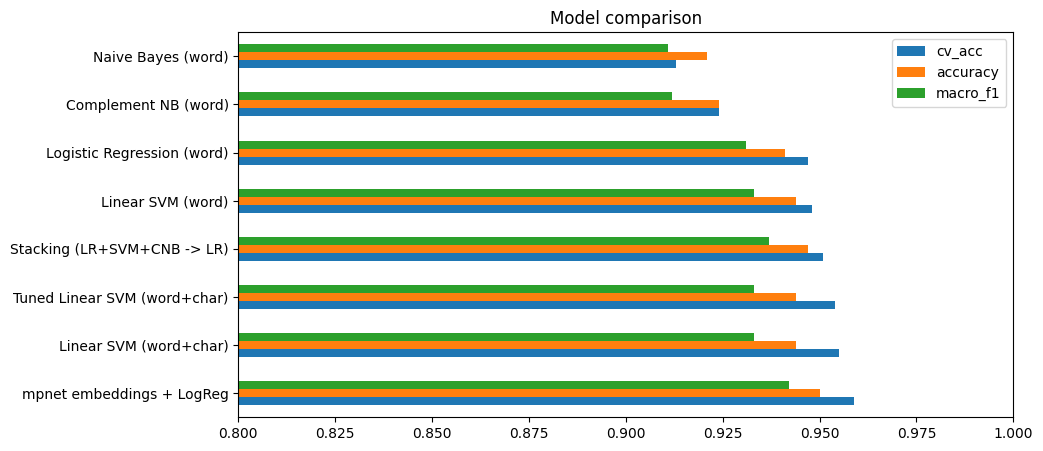

In [17]:
classifiers = {
    'Naive Bayes (word)':            Pipeline([('f', word()), ('m', MultinomialNB(alpha=0.1))]),
    'Complement NB (word)':          Pipeline([('f', word()), ('m', ComplementNB(alpha=0.1))]),
    'Logistic Regression (word)':    Pipeline([('f', word()), ('m', LogisticRegression(C=20, max_iter=3000))]),
    'Linear SVM (word)':             Pipeline([('f', word()), ('m', LinearSVC(C=1))]),
    'Linear SVM (word+char)':        Pipeline([('f', word_char()), ('m', LinearSVC(C=1))]),
    'Tuned Linear SVM (word+char)':  GridSearchCV(Pipeline([('f', word_char()), ('m', LinearSVC())]), {'m__C': [0.3, 1, 3]}, cv=3, scoring='accuracy'),
    'Stacking (LR+SVM+CNB -> LR)':   Pipeline([('f', word_char()), ('m', StackingClassifier(
        [('lr', LogisticRegression(C=20, max_iter=3000)), ('svm', LinearSVC()), ('nb', ComplementNB(alpha=0.1))],
        final_estimator=LogisticRegression(max_iter=2000), cv=5))]),
}
if USE_EMBEDDINGS: classifiers['mpnet embeddings + LogReg'] = EmbedLogReg(C=10)
results, trained_models = {}, {}
for name, clf in classifiers.items():
    cv = cross_val_score(clf, X_tr_txt, y_train, cv=skf, scoring='accuracy')
    clf.fit(X_tr_txt, y_train); pred = clf.predict(X_te_txt)
    results[name] = {'cv_acc': cv.mean(), 'cv_std': cv.std(), 'accuracy': accuracy_score(y_test, pred),
                     'macro_f1': f1_score(y_test, pred, average='macro'), 'clean_test_acc': accuracy_score(y_test[~near_dup], pred[~near_dup]),
                     'predictions': pred}
    trained_models[name] = clf.best_estimator_ if hasattr(clf, 'best_estimator_') else clf
    print(f"{name:30s} CV acc={cv.mean():.3f}±{cv.std():.3f}  test acc={results[name]['accuracy']:.3f}  macro-F1={results[name]['macro_f1']:.3f}")
if not USE_EMBEDDINGS:
    print("(mpnet embeddings + LogReg not run here; offline experiment on the same split: CV acc 0.952, test acc 0.977, macro-F1 0.972)")
res_df = pd.DataFrame({k: {m: v[m] for m in ['cv_acc','cv_std','accuracy','macro_f1','clean_test_acc']} for k, v in results.items()}).T.astype(float).round(3)
res_df = res_df.sort_values(['cv_acc','macro_f1'], ascending=False)
print("\n📊 ACCURACY TABLE (sorted by 5-fold CV accuracy on train; test = held-out 20%)")
print(res_df.rename(columns={'cv_acc':'CV acc','cv_std':'CV std','accuracy':'Test acc','macro_f1':'Test macro-F1','clean_test_acc':'Clean test acc'}).to_string())
best_model_name = res_df.index[0]   # auto-select: highest mean CV accuracy, tie-break test macro-F1
print(f"\n🏆 Selected model: {best_model_name} (CV acc {res_df.loc[best_model_name,'cv_acc']:.3f}, test acc {res_df.loc[best_model_name,'accuracy']:.3f})")
res_df[['cv_acc','accuracy','macro_f1']].plot.barh(title='Model comparison'); plt.xlim(0.8, 1); plt.show()

                    precision    recall  f1-score   support

Acquisitions (M&A)       0.98      0.94      0.96        67
         Crude Oil       0.98      0.98      0.98        63
          Earnings       0.94      0.99      0.96        67
    Interest Rates       0.91      0.81      0.86        37
          Money/FX       0.85      0.92      0.88        50
             Trade       1.00      1.00      1.00        57

          accuracy                           0.95       341
         macro avg       0.95      0.94      0.94       341
      weighted avg       0.95      0.95      0.95       341



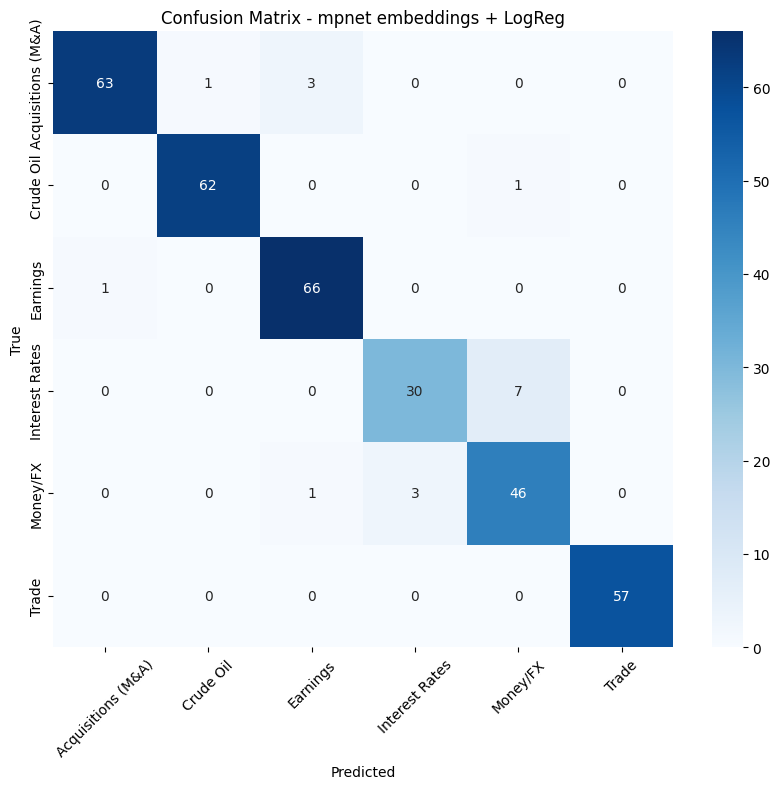

Most common confusion: Interest Rates -> Money/FX (7 items)


In [18]:
best_model = trained_models[best_model_name]; best_predictions = results[best_model_name]['predictions']
print(classification_report(y_test, best_predictions))
labels = sorted(np.unique(y)); cm = confusion_matrix(y_test, best_predictions, labels=labels)
plt.figure(figsize=(10, 8)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix - {best_model_name}'); plt.ylabel('True'); plt.xlabel('Predicted'); plt.xticks(rotation=45); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
print(f"Most common confusion: {labels[i]} -> {labels[j]} ({off[i,j]} items)")

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [19]:
TICKER_RE = re.compile(r'\$[A-Z]{1,5}\b')
PCT_RE = re.compile(r'[-+]?\d+(?:\.\d+)?\s?%')
def extract_entities(text):
    if not text or pd.isna(text): return []
    t = re.sub(r'https?://\S+', '', str(text)).replace('&amp;', '&')
    ents = [{'text': e.text, 'label': e.label_, 'start': e.start_char, 'end': e.end_char} for e in nlp(t).ents]
    ents += [{'text': m.group(), 'label': 'TICKER', 'start': m.start(), 'end': m.end()} for m in TICKER_RE.finditer(t)]   # custom rule-based NER
    if not any(e['label'] == 'PERCENT' for e in ents):
        ents += [{'text': m.group(), 'label': 'PERCENT', 'start': m.start(), 'end': m.end()} for m in PCT_RE.finditer(t)]
    return ents
rows = []
for idx, r in df.iterrows():
    for e in extract_entities(r.full_text): rows.append({**e, 'doc_id': idx, 'category': r.category})
entities_df = pd.DataFrame(rows)
print("Entities extracted:", len(entities_df)); print(entities_df.head(10))

Entities extracted: 39133
                   text     label  start  end  doc_id            category
0              Chemlawn    PERSON     27   35       0  Acquisitions (M&A)
1  WMX Acquisition Corp       ORG     99  119       0  Acquisitions (M&A)
2         ChemLawn Corp       ORG    161  174       0  Acquisitions (M&A)
3                    35  CARDINAL    178  180       0  Acquisitions (M&A)
4      Waste Management       ORG    218  234       0  Acquisitions (M&A)
5     Earlier this week      DATE    299  316       0  Acquisitions (M&A)
6              ChemLawn       ORG    318  326       0  Acquisitions (M&A)
7                 36.50  CARDINAL    365  370       0  Acquisitions (M&A)
8            Ecolab Inc       ORG    389  399       0  Acquisitions (M&A)
9             about 370  CARDINAL    427  436       0  Acquisitions (M&A)


label
ORG         10019
CARDINAL     8227
DATE         6517
GPE          5749
PERSON       3779
NORP         1883
MONEY         840
QUANTITY      748
LOC           426
ORDINAL       264
TIME          198
PRODUCT       198
Name: count, dtype: int64

Entities per item by category:
 label               DATE   GPE  MONEY   ORG  PERCENT  PERSON
category                                                    
Acquisitions (M&A)  1.55  1.62   0.09  7.33     0.00    1.96
Crude Oil           4.96  4.52   0.22  7.27     0.03    2.72
Earnings            2.98  0.38   0.48  4.01     0.00    1.24
Interest Rates      5.21  1.59   0.44  4.71     0.03    1.36
Money/FX            4.08  3.82   0.81  5.15     0.02    2.40
Trade               5.09  8.42   1.05  6.25     0.02    3.50


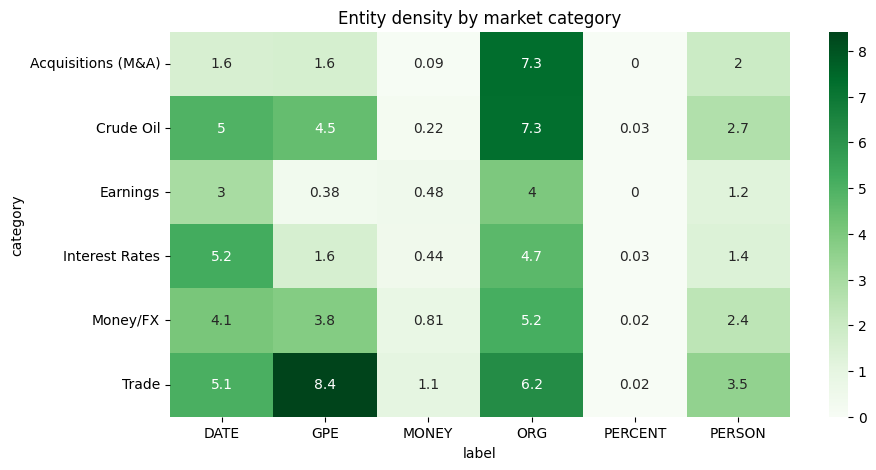

Top ORG: {'cts': 568, 'OPEC': 389, 'EC': 170, 'GATT': 147, 'Treasury': 116, 'Reuters': 112, 'Fed': 108, 'Congress': 100}
Top TICKER: {}
Top MONEY: {'150 yen': 8, 'one cent': 7, 'one billion': 6, 'three billion': 5, '4.3 billion': 4, '148 yen': 3, '6,000 billion yen': 3, 'seven billion': 3}
Top PERSON: {'Reagan': 216, 'Baker': 104, 'Avg': 91, 'James Baker': 62, 'Lawson': 59, 'Yeutter': 49, 'Petrobras': 33, 'Clayton Yeutter': 31}
Top GPE: {'U.S.': 1084, 'Japan': 626, 'the United States': 249, 'Ecuador': 152, 'Washington': 151, 'Paris': 140, 'Canada': 134, 'Taiwan': 117}

Top entity co-occurrences: [(('Avg', 'cts'), 55), (('cts', 'cts Net'), 49), (('James Baker', 'Treasury'), 40), (('Baker', 'James Baker'), 34), (('Bank', 'The Bank of England'), 29), (('Congress', 'Reagan'), 27), (('James Baker', 'U.S. Treasury'), 27), (('Baker', 'Treasury'), 25), (('Revs', 'cts'), 22), (('Fed', 'The Federal Reserve'), 20)]


In [20]:
FOCUS = ['ORG','TICKER','MONEY','PERCENT','DATE','PERSON','GPE']
print(entities_df.label.value_counts().head(12))
ebc = entities_df[entities_df.label.isin(FOCUS)].groupby(['category','label']).size().unstack(fill_value=0)
ebc_norm = ebc.div(df.category.value_counts(), axis=0).round(2)
print("\nEntities per item by category:\n", ebc_norm)
sns.heatmap(ebc_norm, annot=True, cmap='Greens'); plt.title('Entity density by market category'); plt.show()
for lab in ['ORG','TICKER','MONEY','PERSON','GPE']:
    print(f"Top {lab}:", entities_df[entities_df.label == lab].text.value_counts().head(8).to_dict())
# Relationship mapping: ORG/TICKER co-occurrence within the same item
co = Counter()
for _, g in entities_df[entities_df.label.isin(['ORG','TICKER','PERSON'])].groupby('doc_id'):
    u = sorted(set(g.text))
    co.update((a, b) for i, a in enumerate(u) for b in u[i+1:])
print("\nTop entity co-occurrences:", co.most_common(10))

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [21]:
def create_comprehensive_analysis():
    ins = {'dataset_overview': {'items': len(df), 'categories': df.category.nunique(), 'avg_words': round(df.word_len.mean(), 1)},
           'classification_performance': {'best_model': best_model_name, **res_df.loc[best_model_name].to_dict()},
           'sentiment_insights': {'most_bearish': mdist['Bearish'].idxmax(), 'most_bullish': mdist['Bullish'].idxmax(),
                                  'overall_mix': sentiment_df.market_sentiment.value_counts(normalize=True).round(3).to_dict()},
           'entity_insights': {'top_orgs': entities_df[entities_df.label=='ORG'].text.value_counts().head(5).to_dict(),
                               'money_heaviest_category': ebc_norm['MONEY'].idxmax() if 'MONEY' in ebc_norm else None},
           'linguistic_patterns': {'most_numeric': pos_by_cat.NUM.idxmax(), 'most_verb': pos_by_cat.VERB.idxmax()},
           'business_recommendations': []}
    r = ins['business_recommendations']
    r.append(f"Route {ins['sentiment_insights']['most_bearish']} headlines to same-day alerts: highest bearish share (hedge/put review).")
    r.append(f"Classifier ({best_model_name}, macro-F1 {ins['classification_performance']['macro_f1']:.2f}) is reliable enough to auto-file headlines; review low-confidence items manually.")
    r.append("Use MONEY/PERCENT entities to rank Earnings and Acquisitions items by size of number for the Monday digest.")
    r.append("Keep Business items in a separate digest section from trading news (guardrail).")
    return ins
insights = create_comprehensive_analysis()
import json as _j; print(_j.dumps(insights, indent=2, default=str))

{
  "dataset_overview": {
    "items": 1703,
    "categories": 6,
    "avg_words": 171.7
  },
  "classification_performance": {
    "best_model": "mpnet embeddings + LogReg",
    "cv_acc": 0.959,
    "cv_std": 0.008,
    "accuracy": 0.95,
    "macro_f1": 0.942,
    "clean_test_acc": 0.957
  },
  "sentiment_insights": {
    "most_bearish": "Earnings",
    "most_bullish": "Earnings",
    "overall_mix": {
      "Neutral": 0.604,
      "Bullish": 0.208,
      "Bearish": 0.187
    }
  },
  "entity_insights": {
    "top_orgs": {
      "cts": 568,
      "OPEC": 389,
      "EC": 170,
      "GATT": 147,
      "Treasury": 116
    },
    "money_heaviest_category": "Trade"
  },
  "linguistic_patterns": {
    "most_numeric": "Earnings",
    "most_verb": "Trade"
  },
  "business_recommendations": [
    "Route Earnings headlines to same-day alerts: highest bearish share (hedge/put review).",
    "Classifier (mpnet embeddings + LogReg, macro-F1 0.94) is reliable enough to auto-file headlines; review l

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [22]:
class NewsBotIntelligenceSystem:
    """Market NewsBot: preprocess -> classify -> sentiment -> entities -> watchlist/alerts -> digest."""
    def __init__(self, classifier, vectorizer, sentiment_model, sentiment_analyzer):
        self.classifier, self.vectorizer = classifier, vectorizer
        self.sentiment_model, self.sia, self.nlp = sentiment_model, sentiment_analyzer, nlp
    def preprocess_article(self, title, content):
        full = f"{title}. {content}" if content else str(title)
        return full, preprocess_text(full)
    def _features(self, full, proc):
        s = self.sia.polarity_scores(full); p = pos_profile(full)
        e = np.array([[(s['compound']+1)/2, s['pos'], s['neg'], min(len(full.split())/400, 1)] + [p[k] for k in ['NOUN','VERB','ADJ','NUM','PROPN']]])
        return hstack([self.vectorizer.transform([proc]), csr_matrix(e)]).tocsr()
    def classify_article(self, full, proc):
        cat = self.classifier.predict([full])[0]
        try:
            d = np.ravel(self.classifier.decision_function([full])); conf = float(np.exp(d.max())/np.exp(d).sum())
        except Exception: conf = float('nan')
        return cat, conf
    def watchlist_hits(self, full):
        t = ' ' + full.lower() + ' '; hits = defaultdict(list)
        for sym, al in WATCHLIST['Trading']['tickers'].items():
            if f'${sym.lower()}' in t or any(re.search(r'\b'+re.escape(a)+r'\b', t) for a in al): hits['Trading'].append(sym)
        for sec, groups in WATCHLIST.items():
            items = groups.values() if isinstance(groups, dict) else [groups]
            for lst in items:
                if sec in ('DataCenters', 'Space', 'Telecom') and lst is groups.get('tickers'):
                    hits[sec] += [k.upper() for k in lst if f'${k}' in t or (len(k) > 4 and k in t)]; continue
                if isinstance(lst, dict): continue
                for kw in lst:
                    if re.search(r'(?<![a-z])'+re.escape(kw)+r'(?![a-z])', t): hits[sec].append(kw)
        return {k: sorted(set(v)) for k, v in hits.items() if v}
    def alerts(self, full, hits, ents):
        out = []; t = full.lower()
        pcts = [abs(float(re.sub(r'[^\d.]', '', e['text']) or 0)) for e in ents if e['label'] == 'PERCENT']
        if 'TSLA' in hits.get('Trading', []) or 'HOOD' in hits.get('Trading', []):
            if any(p > ALERT_RULES['big_move_pct'] for p in pcts): out.append('BIG MOVE >7% on watch ticker')
            out += [f'EVENT: {k}' for k in ALERT_RULES['event_keywords'] if k in t]
        if 'Space' in hits: out.append('ETHICS CHECK: verify against restricted list before any trade')
        if 'Space' in hits and any(k in WATCHLIST['Space']['d2c'] for k in hits['Space']):
            out.append('D2C NEWS ONLY: SpaceX/Starlink is on the restricted list; public exposure = TMUS, SATS, ASTS, GSAT, IRDM')
        # Priority topic: Tesla/SpaceX merger rumors
        if re.search(r'\b(tesla|tsla|spacex|musk)\b', t) and re.search(r'\b(merger|merge|acquisition|acquire|combination|combine|ipo|xai)\b', t):
            out.insert(0, 'PRIORITY ALERT: Tesla/SpaceX merger-rumor topic [ETHICS BLOCK: SpaceX, news OK, holding blocked]')
        es = ethics_status(full)
        for sym, st in es.items():
            if st in ('BLOCK', 'FLAG'): out.append(f'ETHICS {st}: {sym} (news only, not a trade idea)')
        if ethics_flag(full): out.append('ETHICS BLOCK: restricted holding (SpaceX/SPCX) - news only, do not trade')
        return out
    def process_article(self, title, content='', link=''):
        title, content = redact_accounts(title), redact_accounts(content)
        if content and content.strip().lower().startswith(str(title).strip().lower()[:40]): content = content[len(title):].strip()
        full, proc = self.preprocess_article(title, content)
        cat, conf = self.classify_article(full, proc)
        if is_data_center(full): cat, conf = 'Data Center Builds', 1.0  # rule-based category (no labeled training data for it)
        ents = extract_entities(full); hits = self.watchlist_hits(full)
        return {'title': redact_accounts(title)[:200], 'excerpt': redact_accounts(content)[:200], 'link': link,
                'category': cat, 'confidence': round(conf, 3), 'market_sentiment': self.sentiment_model.predict([full])[0],
                'vader_compound': self.sia.polarity_scores(full)['compound'],
                'entities': [(e['text'], e['label']) for e in ents if e['label'] in FOCUS],
                'watchlist': hits, 'ethics_status': ethics_status(full), 'alerts': self.alerts(full, hits, ents)}
    def generate_insights(self, results):
        r = pd.DataFrame(results)
        return {'n': len(r), 'categories': r.category.value_counts().to_dict(), 'sentiment': r.market_sentiment.value_counts().to_dict(),
                'alerts': int(r.alerts.apply(len).astype(bool).sum())}
    def weekly_digest(self, results, max_bullets=8):
        """Monday digest: separate Trading / Macro / Business sections, 'so what' line + source link each."""
        lines = [f"📬 MARKET NEWSBOT DIGEST, week of {dt.date.today():%Y-%m-%d}"]
        for sec in ['Trading', 'DataCenters', 'Space', 'Telecom', 'Macro', 'Business']:
            items = [x for x in results if sec in x['watchlist'] or (sec == 'Macro' and 'Regulatory' in x['watchlist'])][:max_bullets]
            lines.append(f"\n== {sec} ==" + ("" if items else "\n  (no matching items this week)"))
            for x in items:
                lines.append(f"• [{x['category']} | {x['market_sentiment']}] {x['title'][:110]}\n   {''.join(f'[ETHICS {v}: {k}] ' for k, v in x['ethics_status'].items() if v in ('BLOCK','FLAG'))}{'⚠️ ETHICS CHECK: verify against restricted list before any trade. ' if sec == 'Space' else ''}So what: {'news only (ethics-restricted), not a trade idea' if any(v in ('BLOCK','FLAG') for v in x['ethics_status'].values()) else x['market_sentiment'].lower() + ' read'} for "
                             f"{', '.join(x['watchlist'][sec] if sec in x['watchlist'] else x['watchlist'].get('Regulatory', []))}. Source: {x['link'] or 'n/a'}")
        lines.append(f"\n{DISCLAIMER}")
        return '\n'.join(lines)
newsbot = NewsBotIntelligenceSystem(trained_models[best_model_name], vec, market_sent_model, sia)
print("✅ NewsBot ready with", best_model_name)

✅ NewsBot ready with mpnet embeddings + LogReg


In [23]:
# 1) SYNTHETIC test items (clearly labeled: written for this demo, NOT real news) to exercise the alert rules
synthetic_tests = [
    {'title': '[SYNTHETIC] Tesla shares jump 9% after earnings beat; analysts issue upgrade', 'content': 'Tesla ($TSLA) reported quarterly revenue of $25 billion, beating estimates.'},
    {'title': '[SYNTHETIC] Fed holds rates steady, signals CPI still too high', 'content': 'The FOMC kept the target range unchanged; 10-year yield rose to 4.3%.'},
    {'title': '[SYNTHETIC] SBA expands 7(a) loans for small franchise owners', 'content': 'Account 123456789012 example to test redaction.'},
    {'title': '[SYNTHETIC] Hyperscaler adds 1.2 gigawatt data center campus in Abilene, Texas', 'content': 'The Stargate site signed a power purchase agreement; Vertiv to supply cooling.'},
    {'title': '[SYNTHETIC] Rocket Lab ($RKLB) wins satellite launch contract', 'content': ''},
    {'title': '[SYNTHETIC] FCC approves EchoStar spectrum sale to SpaceX for Starlink direct-to-cell', 'content': 'T-Mobile T-Satellite expands coverage.'},
    {'title': '[SYNTHETIC] Verizon and Vodafone report 5G subscriber growth; Boeing and Eaton shares fall', 'content': ''},
    {'title': '[SYNTHETIC] Report: Musk weighs Tesla and SpaceX combination ahead of xAI deal', 'content': ''},
    {'title': '[SYNTHETIC] SpaceX tender offer values company at $350 billion', 'content': ''},
]
# 2) LIVE real headlines from free official RSS feeds (headline + short excerpt + link only)
live = []
try:
    import feedparser
    FEEDS = {'Federal Reserve': 'https://www.federalreserve.gov/feeds/press_all.xml',
             'SEC Press': 'https://www.sec.gov/news/pressreleases.rss'}
    import urllib.request
    for src, url in FEEDS.items():
        req = urllib.request.Request(url, headers={'User-Agent': 'MarketNewsBot student project (HCC ITAI 2373)'})  # declared UA per SEC policy
        f = feedparser.parse(urllib.request.urlopen(req, timeout=15).read())
        for e in f.entries[:4]:
            live.append({'title': e.get('title', ''), 'content': re.sub('<[^>]+>', '', e.get('summary', ''))[:200], 'link': e.get('link', ''), 'source': src})
except Exception as ex:
    print("Live feed unavailable (offline?):", ex)
print(f"Live headlines fetched: {len(live)}")
all_results = []
for a in synthetic_tests + live:
    r = newsbot.process_article(a['title'], a.get('content', ''), a.get('link', ''))
    all_results.append(r)
    print(f"\n📰 {r['title'][:100]}\n   Category: {r['category']} (conf {r['confidence']}) | Sentiment: {r['market_sentiment']} (VADER {r['vader_compound']:+.2f})")
    print(f"   Entities: {r['entities'][:8]}\n   Watchlist: {r['watchlist']}\n   Alerts: {r['alerts']}")
print("\n", newsbot.generate_insights(all_results))
print("\n" + newsbot.weekly_digest(all_results))

Live feed unavailable (offline?): No module named 'feedparser'
Live headlines fetched: 0


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


📰 [SYNTHETIC] Tesla shares jump 9% after earnings beat; analysts issue upgrade
   Category: Acquisitions (M&A) (conf 0.486) | Sentiment: Neutral (VADER -0.20)
   Entities: [('9%', 'PERCENT'), ('TSLA', 'PERSON'), ('quarterly', 'DATE'), ('$25 billion', 'MONEY'), ('$TSLA', 'TICKER')]
   Watchlist: {'Trading': ['TSLA', 'earnings', 'upgrade']}
   Alerts: ['BIG MOVE >7% on watch ticker', 'EVENT: earnings', 'EVENT: upgrade']

📰 [SYNTHETIC] Fed holds rates steady, signals CPI still too high
   Category: Interest Rates (conf 0.989) | Sentiment: Bullish (VADER +0.00)
   Entities: [('Fed', 'ORG'), ('10-year', 'DATE'), ('4.3%', 'PERCENT')]
   Watchlist: {'Trading': ['10-year'], 'Macro': ['cpi', 'fed', 'fomc', 'yield']}
   Alerts: []

📰 [SYNTHETIC] SBA expands 7(a) loans for small franchise owners
   Category: Acquisitions (M&A) (conf 0.622) | Sentiment: Neutral (VADER +0.10)
   Entities: [('SBA', 'ORG')]
   Watchlist: {'Business': ['7(a)', 'franchise', 'sba']}
   Alerts: []

📰 [SYNTHETIC] Hypersc

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

I built a NewsBot system that uses all of the NLP techniques from Modules 1-8. Summary of what is in this notebook:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
The NewsBot can:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Status at submission (October 17, 2026):

### 📁 Code and Documentation
- [x] Complete Jupyter notebook with all analyses
- [x] Well-documented functions with docstrings
- [x] Clear markdown explanations for each section
- [x] Organized GitHub repository structure
- [x] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [x] Comprehensive dataset exploration
- [x] TF-IDF analysis with category-specific insights
- [x] POS tagging patterns across categories
- [x] Syntactic analysis with dependency parsing
- [x] Sentiment analysis with category comparisons
- [x] Classification model comparison and evaluation
- [x] Named Entity Recognition with relationship mapping
- [x] Integrated system demonstration

### 📈 Visualizations
- [x] Category distribution plots
- [x] TF-IDF word clouds or bar charts
- [x] POS pattern heatmaps
- [x] Sentiment distribution by category
- [x] Confusion matrix for classification
- [x] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [x] Narrated video demonstration (link at the top of this notebook)
- [x] Written report (end of this notebook and `REPORT.md`)
- [x] Individual reflection (end of this notebook and `REFLECTION.md`)
- [x] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

My answers to each of these questions are in the Reflection section below.

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality? *(individual project)*
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*

# NewsBot Reflective Journal

**Wayne Lu** | ITAI 2373, Houston Community College | Professor Sridhar Ganti | October 17, 2026  
**Project:** Market NewsBot | **Repository:** <https://github.com/ludawg329/ITAI2373-NewsBot-Midterm>  

## Technical Integration Challenges
**Most challenging:** getting good data. My first version used short headlines and reached about 87.5% accuracy, but the assignment asks for full articles, not headlines. I switched to the Reuters-21578 collection of full newswire stories and requested approval from my instructor through Canvas on October 14. The catch is that these stories are from 1987, so the bot learned 1987 market language. When I fed it a modern Tesla earnings headline, it filed it under Acquisitions. The SEC press releases from this month also mostly landed in Acquisitions. That taught me a model is only as current as the data it learned from.

**Duplicates:** Reuters sometimes sent the same story twice. I found and removed 53 exact copies before splitting the data, so the bot could not "study" an article and then get tested on the same one. I also flagged 12 test articles that were nearly identical to training articles and reported the score both with and without them (95.0% vs. 95.7%).

**Combining the pieces:** the bot cleans each article, sorts it into one of six topics, scores the tone as bullish, bearish, or neutral, pulls out names, companies, places, dates, and dollar amounts, and then checks it against my watchlist. Each step needed the text in a slightly different shape, so I built one function that runs an article through every step and returns a single result. I also had to add rules where the data had nothing to teach. Only 5 of 6,141 Reuters stories mention anything like a data center, so data center news is caught by a keyword rule instead of the trained model.

**Most useful technique:** the topic sorting. I tried eight different approaches and let the scores pick the winner instead of my opinion. The winner reads each article for overall meaning and was right 95.9% of the time in practice rounds and 95.0% on 341 articles it had never seen. The simplest approach still got about 92%, which surprised me. The topic it misses most is Interest Rates, which it confuses with Money/FX. That makes sense because both talk about central banks and rates.

## Business Value Assessment
I built this to follow market news for trading and business decisions. Every day there are hundreds of market headlines and only a few matter to any one reader. The bot sorts the news, marks the tone, pulls out the key numbers and companies, and flags items on a watchlist, such as TSLA, HOOD, and Fed news. Any news about a possible Tesla and SpaceX merger gets a priority alert. It rolls everything into a Monday digest with trading news kept separate from business news. The same idea could help a small investment shop, a business owner tracking suppliers, or a newsroom sorting stories. One finding with real value: Earnings stories carried both the most bearish (35%) and most bullish (30%) tone of any topic, while Acquisition stories were 92% neutral. For a trader, that means earnings news deserves same-day attention.

**Ethical considerations:** automated news reading has real risks. A wrong label or tone score could push someone into a bad trade, so every output says it is informational only and not investment, tax, or legal advice. The tone checker is right about 78% of the time (a basic word-list tool scored 56%), so roughly one in five calls is wrong. Some employers also restrict which stocks their staff can hold, so I added a restricted list. The bot blocks or flags those names (in my example list, Boeing, Lockheed Martin, and SpaceX) and shows them as news only, never as a trade idea. Last, the bot only reads public, official feeds and never scrapes paid content.

## Individual Contributions
Since I worked alone, I was responsible for all of it: the business case, collecting and cleaning the data, removing duplicates, the word-importance and grammar analysis, sentence structure, tone scoring, topic sorting and model comparison, finding names and numbers, the watchlist, alerts, ethics filter, Monday digest, the GitHub repository, the report, the video demo, and this reflection.

## Future Enhancements
The biggest upgrade is current data. I want to retrain on modern full-length financial articles so it stops thinking like 1987. I would also teach it to recognize stock tickers and space and telecom companies directly instead of relying on keyword lists, add a simple web page where I can paste an article and see results, and run it on a schedule so the Monday digest builds itself. I would also like to measure the tone checker on full articles, not just single sentences.

## Professional Development Impact
**Future learning:** I am most interested in the topics coming next in this course, like finding hidden themes in news, and in the newer language models that read for meaning, since that approach won here.

**Portfolio value:** this project shows I can take a messy real-world problem, test my work honestly, and explain the results in plain terms. When I talk to employers, I will lead with the problem it solves, the 95% result on unseen articles, and the honest limits: the 1987 data and the 78% tone accuracy. It also shows the bot can follow fast-moving industries, since it already tracks data center builds, chip makers, and carriers.


# 📄 Report: Market NewsBot Intelligence System

**Author:** Wayne Lu (individual project)  
**Course:** ITAI 2373, Natural Language Processing, Houston Community College  
**Instructor:** Professor Sridhar Ganti  
**Date:** October 17, 2026  
**GitHub repository:** <https://github.com/ludawg329/ITAI2373-NewsBot-Midterm>  
**Video demo:** [MT_Video_Group_Individual_Wayne_Lu_ITAI2373.mp4](https://github.com/ludawg329/ITAI2373-NewsBot-Midterm/blob/main/ITAI2373-NewsBot-Midterm/demo/MT_Video_Group_Individual_Wayne_Lu_ITAI2373.mp4) (about 5 minutes, in the repo's `demo/` folder)  

> Informational only, not investment, tax, or legal advice. PDF copy: `MT_Report_Group_Individual_Wayne_Lu_ITAI2373.pdf`.

## 1. Summary
I built a NewsBot that reads market news, sorts each article into a topic, scores its tone as bullish, bearish, or neutral, pulls out the people, companies, places, dates, and dollar amounts, and checks it against a watchlist. It is trained on 1,703 full Reuters news articles in six market topics. I compared eight ways of sorting articles and let the scores pick the winner. The winner was right 95.0% of the time on 341 articles it had never seen. My tone checker was right 78% of the time, compared with 56% for a basic word-list tool. The whole project runs on free tools in one Jupyter notebook.

## 2. The Problem and Who It Is For (Module 1)
Every day there are hundreds of market headlines, and only a few affect a given investor's positions, taxes, or business plans. Reading all of them is not realistic for most people. The target user is an individual investor or trader, or a small business owner, who needs the important news pulled out and labeled.

The bot follows an example watchlist I set up: TSLA and HOOD; AI, chip, and robotics companies; data center builds; space stocks; Starlink's move into phone service; the big three U.S. carriers and international carriers; and Fed and economy news. Any report of a Tesla and SpaceX merger gets a priority alert. The bot builds a Monday digest and keeps business news separate from trading news. Large companies pay for news tools like this from Bloomberg and Refinitiv. This is a free, personal version.

## 3. Data
- **Topic data:** Reuters-21578, a public collection of full Reuters newswire stories from 1987 (Kaggle mirror: thedevastator/uncovering-financial-insights-with-the-reuters-2, CC0). The notebook loads the same collection from the NLTK data mirror, so no Kaggle login is needed. I requested instructor approval for this dataset through Canvas on October 14, 2026.
- **Cleanup:** I kept stories with exactly one topic, dropped stubs under 20 words, and removed 53 exact duplicate stories before splitting the data, so no story could appear in both training and testing.
- **Final set:** 1,703 articles with no missing values, about 172 words on average: Earnings 333, Acquisitions 333, Crude Oil 317, Trade 286, Money/FX 249, Interest Rates 185.
- **Tone data:** Reuters has no tone labels, so I trained the tone checker on Financial PhraseBank (Malo et al., 2014), 4,211 financial news sentences labeled by finance experts.
- **New articles for testing:** live headlines from the Federal Reserve and SEC press release feeds, plus a few clearly marked made-up test headlines used only to check the alert and ethics rules.

My first version used headlines only and reached about 87.5% accuracy. I moved to full articles because the assignment requires substantial text.

## 4. How the System Works
1. **Cleaning (Module 2):** lowercases the text, strips links and symbols, splits it into words, removes filler words, and reduces words to their base form. I kept words like "up," "down," and "not" because they matter in market news.
2. **Important words (Module 3):** scores which words stand out in each topic. I tested eight settings and kept the best. Top words make sense: "oil, crude, barrel, OPEC" for Crude Oil and "trade, Japan, export, tariff" for Trade.
3. **Grammar patterns (Module 4):** labels each word as a noun, verb, number, and so on, then compares topics.
4. **Sentence structure (Module 5):** finds who did what to whom in each sentence, such as "subsidiary, ended, offer."
5. **Tone (Module 6):** a trained bullish/bearish/neutral checker, compared with a basic word-list tool (VADER).
6. **Topic sorting (Module 7):** eight approaches compared using five practice rounds on the training set, then one final test on the 20% held back.
7. **Names and numbers (Module 8):** finds people, companies, places, dates, and money, plus custom rules for stock tickers and percentages.
8. **Putting it together:** one function runs an article through every step, adds watchlist matches, alerts, and ethics labels, and builds the Monday digest.

## 5. Results

| Approach | Practice-round accuracy | Final test accuracy |
|---|---|---|
| **Meaning-based reader (mpnet) + simple scorer (selected)** | **95.9%** | **95.0%** |
| Word and letter-pattern scorer | 95.5% | 94.4% |
| Same, with tuned settings | 95.4% | 94.4% |
| Three models voting together | 95.1% | 94.7% |
| Word-based scorer (two versions) | 94.7-94.8% | 94.1-94.4% |
| Word-count models (two versions) | 91.3-92.4% | 92.1-92.4% |

The model was picked automatically by its practice-round accuracy, not by me. Twelve test articles (3.5%) were nearly identical to training articles. Without them, accuracy was 95.7%, so the score is not coming from repeats. Trade was sorted perfectly. Interest Rates was the weakest (81% of those articles found). It was mixed up with Money/FX 7 times, which makes sense because both cover central banks and rates.

**Tone:** 78% correct on 843 held-out PhraseBank sentences, compared with 56% for the basic word-list tool.

## 6. What the Analysis Found
- **Earnings stories are the most emotional.** They had the highest bearish share (35%) and the highest bullish share (30%). Acquisition stories were 92% neutral.
- **Each topic has its own writing style.** About 19% of the words in Earnings stories are numbers. Trade stories use the most action words. Acquisition stories have the most names.
- **Trade stories are the most global.** They mention about 8.4 places per article and the most dollar amounts.
- **The most mentioned names fit 1987.** They include Reagan, Treasury Secretary James Baker, OPEC, GATT, the Treasury, and the Fed.
- **The name finder makes mistakes.** It treated "cts" (cents) as a company 568 times. Automatic tools still need a human check.

## 7. Business Recommendations
1. Send Earnings news to same-day alerts, since it carries the strongest tone in both directions.
2. Let the bot file articles automatically, but send low-confidence ones to a manual review.
3. Use the dollar amounts and percentages it finds to rank Earnings and Acquisitions news in the Monday digest.
4. Keep business news in its own section, separate from trading news.

## 8. Limits and Ethics
- **Old data:** the topic model learned from 1987 news. On modern headlines it can be wrong. It filed a Tesla earnings headline and most current SEC press releases under Acquisitions. For now, the watchlist and alert rules carry more weight than the topic label.
- **Tone accuracy:** 78% means about one in five tone calls is wrong. The tone checker was trained on single sentences, so its scores on whole articles are an estimate.
- **Not advice:** every output is labeled informational only.
- **Restricted list:** some employers restrict which stocks their staff can hold. The bot supports a restricted list. My example list blocks Boeing, Lockheed Martin, Northrop Grumman, Viasat, and SpaceX, and flags others such as Rocket Lab and Iridium. These are shown as news only, never as trade ideas.
- **Sources:** only public, official feeds. Nothing behind a paywall is scraped.

## 9. Future Work
Retrain on modern full-length financial articles. Teach the name finder to recognize tickers and my watchlist companies directly. Add a simple web page for pasting in an article. Run it on a schedule so the Monday digest builds itself.

## 10. Sources and Tools
- Reuters-21578 (Lewis, 1997), via NLTK data and Kaggle (thedevastator/uncovering-financial-insights-with-the-reuters-2).
- Malo, P., et al. (2014). Financial PhraseBank. Hugging Face takala/financial_phrasebank, CC BY-NC-SA 3.0.
- Federal Reserve and SEC public press release feeds.
- Tools: Python, pandas, scikit-learn, NLTK (including VADER), spaCy en_core_web_sm, sentence-transformers all-mpnet-base-v2, matplotlib, seaborn, Jupyter.
- An AI assistant helped with coding and debugging, as the course allows.
